<a href="https://colab.research.google.com/github/bcramp/ML/blob/main/HW7/wine_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

HW 7

Title: Unsupervised Chemical Segmentation on the Wine Recognition Dataset

Name: Brennen Cramp

Date: 11/7/2026

---

# Task 1: Dataset Loading and Dimensionality Inspection

The following code cell imports the Wine Recognition dataset from the Scikit-Learn Dataset repository and inspects the dimensionality of the dataset.

- This data is extracted into features (X) and target (y) where dimensionality inspection metrics, feature summary statistics, and missing value counts are printed.
- The data is then standardized using the StandardScaler since all values are numerical (i.e. none are categorical).
- Finally, 2 box plots are created onto a figure to show the feature distributions before and after scaling.

--- Dataset Dimensionality Inspection ---
Total Samples: 178
Total Features: 13
Dataset Shape (Samples, Features): (178, 13)
Target Classes: ['class_0' 'class_1' 'class_2']

Class Distribution:
 target
0    59
1    71
2    48
Name: count, dtype: int64
-----------------------------------------

--- Feature Summary Statistics ---
                                    mean         std     min      max
alcohol                        13.000618    0.811827   11.03    14.83
malic_acid                      2.336348    1.117146    0.74     5.80
ash                             2.366517    0.274344    1.36     3.23
alcalinity_of_ash              19.494944    3.339564   10.60    30.00
magnesium                      99.741573   14.282484   70.00   162.00
total_phenols                   2.295112    0.625851    0.98     3.88
flavanoids                      2.029270    0.998859    0.34     5.08
nonflavanoid_phenols            0.361854    0.124453    0.13     0.66
proanthocyanins                 1.590899

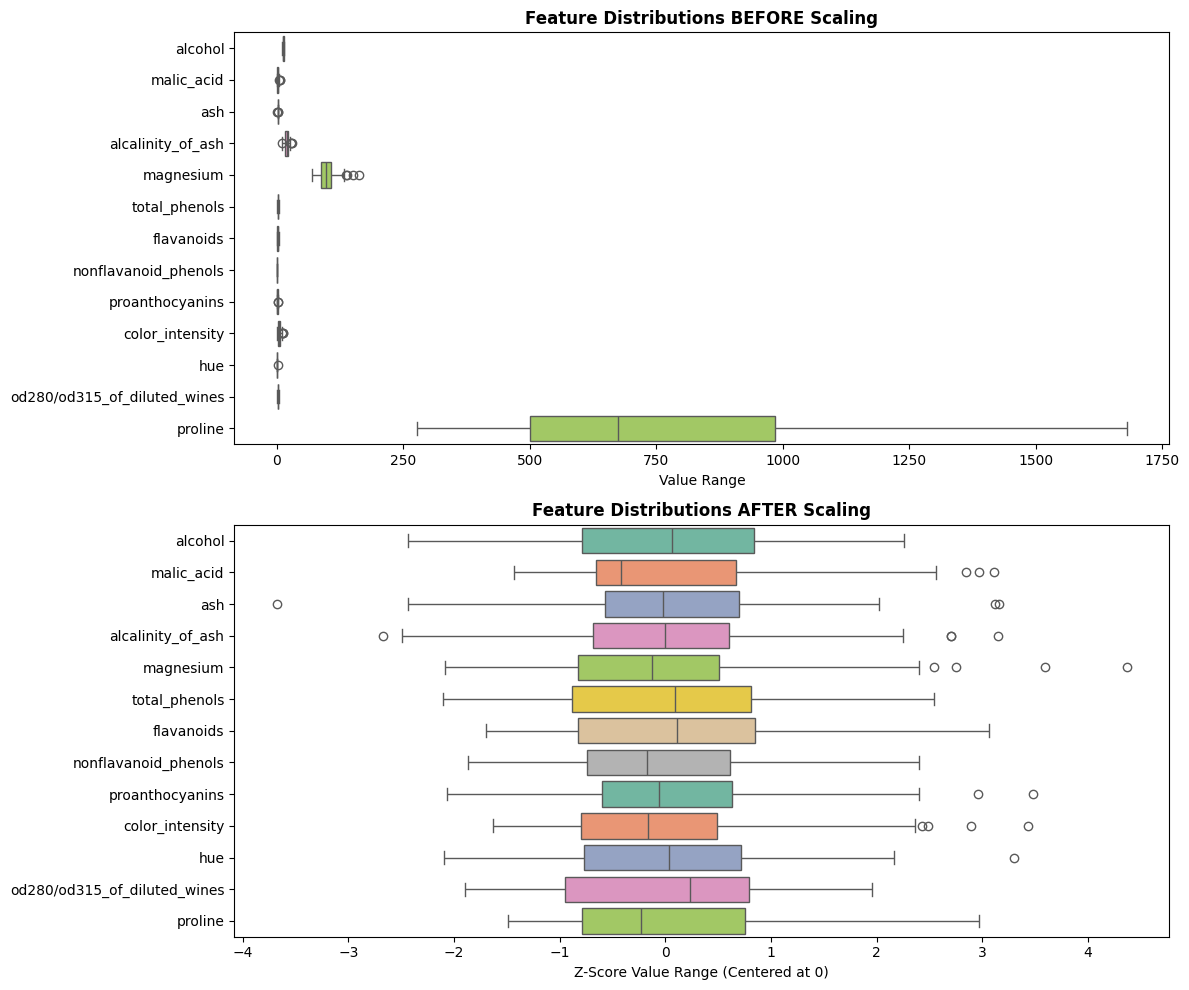

In [57]:
# Import Pandas for handling tabular data
# Import NumPy for handling scientific computing and math operations
# Import the Matplotlib.pyplot for handling visualization tools
# Import Seaborn for making box plots
# Import Scikit-Learn's load_wine to get the dataset
# Import Scikit-Learn's preprocessing to get the StandardScaler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

# Loads the wine dataset as a pandas DataFrame for ease of analysis
wine = load_wine(as_frame=True)
X = wine.data
y = wine.target

# Displays basic dataset dimensions and class distribution
n_samples, n_features = X.shape
print("--- Dataset Dimensionality Inspection ---")
print(f"Total Samples: {n_samples}")
print(f"Total Features: {n_features}")
print("Dataset Shape (Samples, Features):", X.shape)
print("Target Classes:", wine.target_names)
print("\nClass Distribution:\n", pd.Series(y).value_counts().sort_index())
print("-----------------------------------------\n")

# Displays the feature summary stats
print("--- Feature Summary Statistics ---")
print(X.describe().T[['mean', 'std', 'min', 'max']])
print("-----------------------------------------\n")

# Displays the missing values across the features
missing_count = X.isnull().sum()
print("--- Missing Value Check ---")
print(f"Total Missing Values in Dataset: \n{missing_count}")
print("-----------------------------------------\n")

# Standardizes all 13 features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=wine.feature_names)

# Styling for the combined plot
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Before Scaling
sns.boxplot(data=X, ax=axes[0], orient="h", palette="Set2")
axes[0].set_title("Feature Distributions BEFORE Scaling", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Value Range")

# After Scaling
sns.boxplot(data=X_scaled_df, ax=axes[1], orient="h", palette="Set2")
axes[1].set_title("Feature Distributions AFTER Scaling", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Z-Score Value Range (Centered at 0)")

plt.tight_layout()
plt.show()


# Task 2: Elbow and Silhouette Plots

The following code cell will iterate k (1-10) for K-Means clustering on the scaled features (X_scaled) and compute the Within-Cluster Sum of Squares (WCSS/Inertia) and Silhouette Coefficient. This code will also compute and plot differeing methods side-by-side.

- Computes and plots the Elbow Method Curve.
- Computes and plots the Silhouette Scores curve for k in [2, 10], printing the optimal k value suggested by both metrics.

--- Task 2: Elbow and Silhouette Plots ---
--- Clustering Metric Analysis ---
Optimal k-value suggested by Elbow Method: Check plot for the inflection point (most likely k=3)
Optimal k-value suggested by Silhouette Score: 3
-----------------------------------



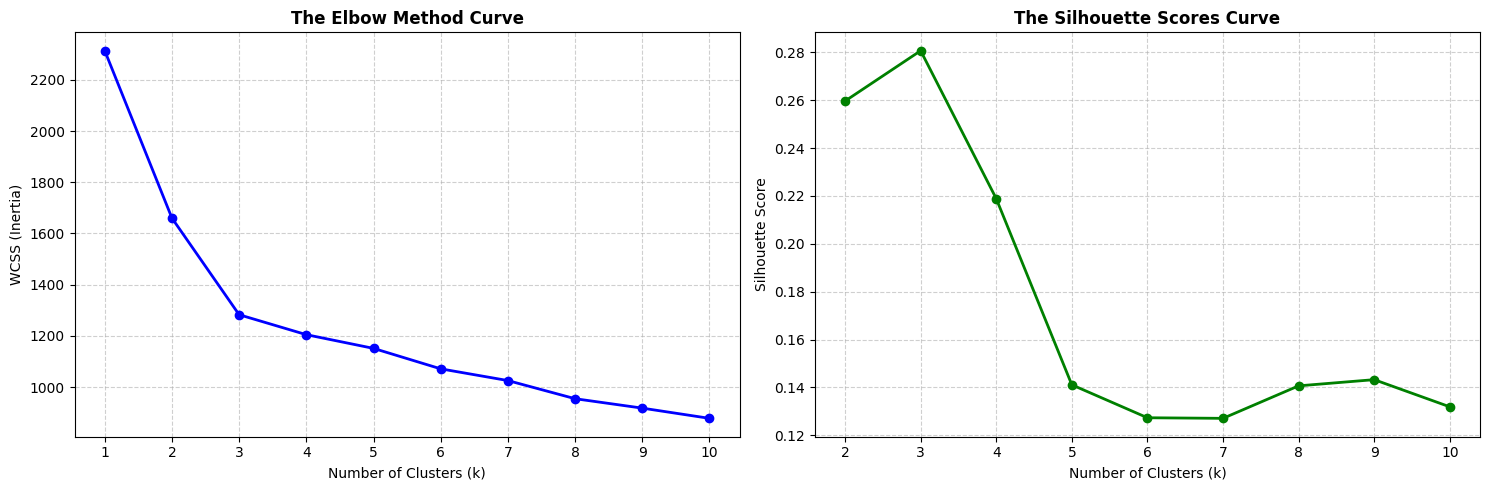

In [58]:
# Import needed Scikit-Learn libraries for clustering and calculations
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Task 2: Elbow and Silhouette Plots
print("--- Task 2: Elbow and Silhouette Plots ---")

# Create lists to hold the eval metrics
wcss = []
sil_scores = []
k_range = range(1, 11)

# Creates seed to be consistent (50) among all tasks
seed = 50

# Iterate k from 1 to 10
for k in k_range:
    # I will use n_init='auto' to match Scikit-Learn standards and ensure reproducibility
    kmeans = KMeans(n_clusters=k, random_state=seed, n_init='auto')
    kmeans.fit(X_scaled)

    # Adds the WCCS/Inertia to list
    wcss.append(kmeans.inertia_)

    # Check if the k is >= 2 since silhouette score requires at least 2 clusters
    if k >= 2:
        # Calc the score and add to the list
        score = silhouette_score(X_scaled, kmeans.labels_)
        sil_scores.append(score)

# Determine optimal k vals and for silhouette, it is just the absolute highest score
optimal_k_silhouette = range(2, 11)[np.argmax(sil_scores)]

# Displays the optimal k vals for each
print("--- Clustering Metric Analysis ---")
print("Optimal k-value suggested by Elbow Method: Check plot for the inflection point (most likely k=3)")
print(f"Optimal k-value suggested by Silhouette Score: {optimal_k_silhouette}")
print("-----------------------------------\n")

# Styling for the combined plot
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Section for the elbow method
axes[0].plot(k_range, wcss, marker='o', color='blue', linewidth=2, markersize=6)
axes[0].set_title('The Elbow Method Curve', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)', fontsize=10)
axes[0].set_ylabel('WCSS (Inertia)', fontsize=10)
axes[0].set_xticks(k_range)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Section for the silhouette scores
axes[1].plot(range(2, 11), sil_scores, marker='o', color='green', linewidth=2, markersize=6)
axes[1].set_title('The Silhouette Scores Curve', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (k)', fontsize=10)
axes[1].set_ylabel('Silhouette Score', fontsize=10)
axes[1].set_xticks(range(2, 11))
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


# Task 3: Apply PCA and Fit K-Means Model

The following code cell compresses the 13D standardized dataset down to 2D using Principal Component Analysis (PCA) and fits a K-Means model (k=3) directly on those 2 principal components. The code cell will also display the Voronoi decision boundaries using a dense background mesh grid (with plt.contourf found in https://github.com/bforoura/ML26/blob/main/Module8_Unsupervised/customer_segmentation.ipynb) to show where the model divides the classes.

- Applies PCA to reduce the 13 scaled features (X_scaled) to 2 PCs.
- Fits a K-Means model (k=3) on the new 2D plot space.
- Adds decision boundaries to the plot using the Voronoi method.

--- Task 3: Apply PCA and Fit K-Means Model ---


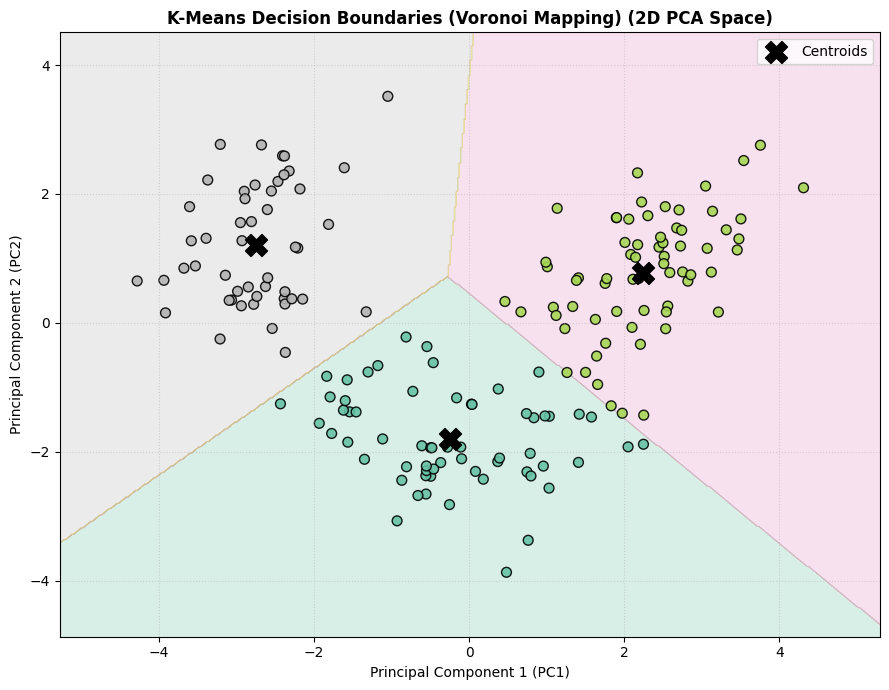

In [59]:
# Import Scikit-Learn's PCA library
from sklearn.decomposition import PCA

# Task 3: Apply PCA and Fit K-Means Model
print("--- Task 3: Apply PCA and Fit K-Means Model ---")

# Apply the PCA to reduce the 13 scaled features down to 2 PCs
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Fits a K-Means model (k=3) directly on the 2D projected space and uses my previous seed of 50
kmeans_pca = KMeans(n_clusters=3, random_state=seed, n_init='auto')
kmeans_pca.fit(X_pca)

# Extract labels and cluster centroids in the 2D space
labels_pca = kmeans_pca.labels_
centroids_pca = kmeans_pca.cluster_centers_

# Creates a mesh grid to plot decision boundaries (Voronoi regions)
x_min = X_pca[:, 0].min() - 1
x_max = X_pca[:, 0].max() + 1
y_min = X_pca[:, 1].min() - 1
y_max = X_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

# Predicts the cluster assignment for every coord on the map
Z = kmeans_pca.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Styling for the plot
plt.figure(figsize=(9, 7))

# Plot the decision boundaries using contour regions
plt.contourf(xx, yy, Z, alpha=0.25, cmap='Set2')

# Scatter plot of the samples proj in PCA space
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_pca, cmap='Set2', edgecolor='k', s=50, alpha=0.9)

# Marks and labels the black cluster centroids
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], marker='X', s=250, color='black', label='Centroids')

plt.title("K-Means Decision Boundaries (Voronoi Mapping) (2D PCA Space)", fontsize=12, fontweight='bold')
plt.xlabel("Principal Component 1 (PC1)", fontsize=10)
plt.ylabel("Principal Component 2 (PC2)", fontsize=10)
plt.legend(loc="upper right")
plt.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()


# Task 4: Soft Clustering Distance Heatmap

The following code cell fits a K-Means model with k=3 on the full 13D feature scaled space where 5 representative samples with be extracted across the dataset. The Euclidean distance is calculated from each of these 5 samples to all 3 cluster centroids and the distance matrix is plotted as a heatmap, where the minimum value in each row represents the sample's hard cluster assignment.

- Selects 5 representative wine samples from the dataset.
- Using the fitted 13-feature K-Means model (k=3), the distance matrix is computed.
- Generate and display a heatmap visualizing the soft clustering distance profiles across all 3 cluster centroids, highlighting the minimum distance corresponding to each sample's hard cluster assignment.

--- Task 4: Soft Clustering Distance Heatmap ---


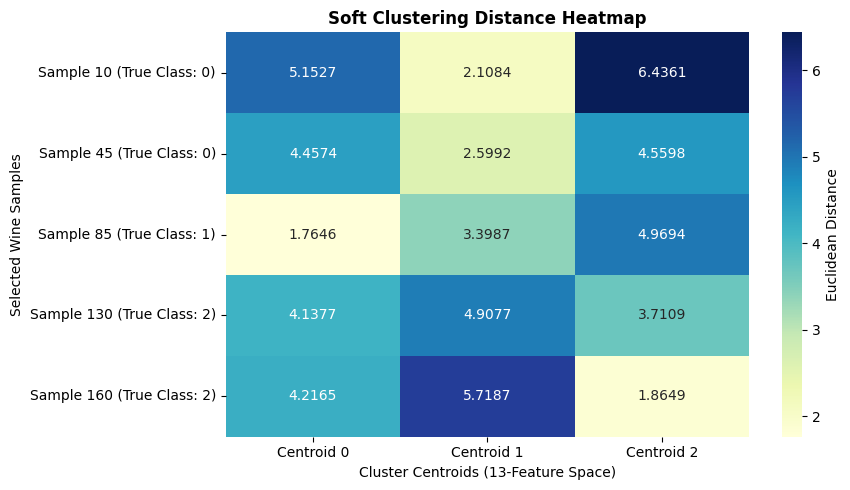

In [60]:
# Task 4: Distance Profiles Heatmap for 5 Representative Samples
print("--- Task 4: Soft Clustering Distance Heatmap ---")

# Fits the K-Means model (k=3) on the full 13D scaled feature space
kmeans_13f = KMeans(n_clusters=3, random_state=seed, n_init='auto')
kmeans_13f.fit(X_scaled)

# Select 5 representative wine samples spread across different regions of the dataset where I picked
# strategic indices to ensure a mix of clusters
sample_indices = [10, 45, 85, 130, 160]
samples = X_scaled[sample_indices]

# Compute distances from each new point to all k centroids
distance_matrix = kmeans_13f.transform(samples)

# Wrap in a DataFrame for seamless presentation and labeling
heatmap_df = pd.DataFrame(
    distance_matrix,
    index=[f"Sample {i} (True Class: {y[i]})" for i in sample_indices],
    columns=["Centroid 0", "Centroid 1", "Centroid 2"]
)

# Styling for the plot
plt.figure(figsize=(9, 5))

# Annotates each point with the distance
sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu",
    cbar_kws={'label': 'Euclidean Distance'}
)

plt.title("Soft Clustering Distance Heatmap", fontsize=12, fontweight='bold')
plt.ylabel("Selected Wine Samples", fontsize=10)
plt.xlabel("Cluster Centroids (13-Feature Space)", fontsize=10)

plt.tight_layout()
plt.show()


# Task 5: DBSCAN Clustering and Evaluation

The following code cell utilizes Density-Based Spatial Clustering of Applications with Noise (DBSCAN) on the full 13D scaled space. The code will also tune the two hyperparameters for DBSCAN (eps and min_samples), print the clusters and noise points, and plot the results back onto the 2D PCA space.

- Fits a DBSCAN model on the 13D scaled feature space.
- Experiments with the two needed hyperparameter settings (eps and min_samples).
- Prints the number of identified clusters and noise points.
- Adds the DBSCAN assignments on the 2D PCA projection space, clearly distinguishing noise points from core cluster members.

--- Task 5: DBSCAN Clustering and Evaluation ---
--- DBSCAN Execution Metrics ---
Number of Identified Clusters: 3
Number of Noise Points (-1): 32
--------------------------------



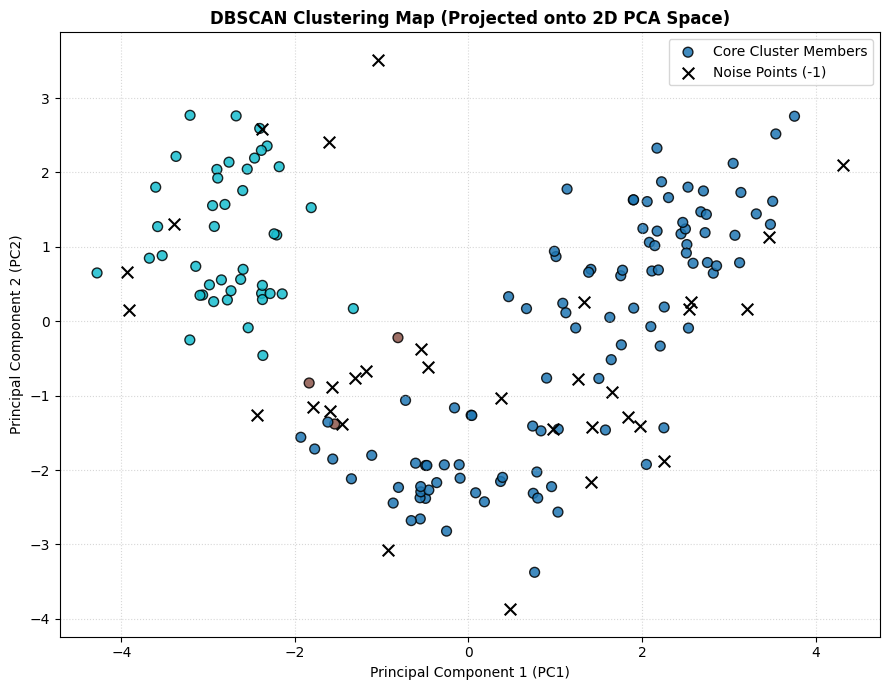

In [61]:
# Imports Scikit-Learn's DBSCAN library
from sklearn.cluster import DBSCAN

# Task 5: DBSCAN Clustering and Evaluation
print("--- Task 5: DBSCAN Clustering and Evaluation ---")

# After experimenting with the hyperparams, I found 2.3 and 3 to be the best fits. Here were the experimented values:
# Originally, I tried 2.3 and 4 which got me 2 clusters and 36 noise points
# Next, I tried 2.0 and 3 which got me 5 clusters and 64 noise points
# Finally, I tried 2.3 and 3 which got me 3 clusters and 32 noise points
# I played around more but it looks like 2.3 and 3 got me the best fit!
dbscan = DBSCAN(eps=2.3, min_samples=3)
dbscan_labels = dbscan.fit_predict(X_scaled)

# Extracts and analyzes clusters vs noise points
unique_labels = set(dbscan_labels)
num_clust_db = len(unique_labels) - (1 if -1 in unique_labels else 0)
num_noise_db = list(dbscan_labels).count(-1)

print("--- DBSCAN Execution Metrics ---")
print(f"Number of Identified Clusters: {num_clust_db}")
print(f"Number of Noise Points (-1): {num_noise_db}")
print("--------------------------------\n")

# Styling for the plot
plt.figure(figsize=(9, 7))

# Filters noise and plot the core feats
filtered_noise = dbscan_labels != -1
plt.scatter(
    X_pca[filtered_noise, 0],
    X_pca[filtered_noise, 1],
    c=dbscan_labels[filtered_noise],
    cmap='tab10',
    s=50,
    edgecolor='k',
    alpha=0.85,
    label='Core Cluster Members'
)

# Filters core feats and plots noise
filtered_core = dbscan_labels == -1
plt.scatter(
    X_pca[filtered_core, 0],
    X_pca[filtered_core, 1],
    color='black',
    marker='x',
    s=70,
    linewidth=1.5,
    label='Noise Points (-1)'
)

plt.title("DBSCAN Clustering Map (Projected onto 2D PCA Space)", fontsize=12, fontweight='bold')
plt.xlabel("Principal Component 1 (PC1)", fontsize=10)
plt.ylabel("Principal Component 2 (PC2)", fontsize=10)
plt.legend(loc="upper right")
plt.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()


# Task 6: HDBSCAN Clustering and Evaluation

The following code cell utilizes Hierarchical Density-Based Spatial Clustering of Applications with Noise (HDBSCAN) (using min_cluster_size=5 and min_samples=5) on the full 13D scaled space. The code will also tune the two hyperparameters for DBSCAN (eps and min_samples), print the clusters and noise points, and plot the results back onto the 2D PCA space.

- Fits an HDBSCAN model (using min_cluster_size=5 and min_samples=5) on the 13D scaled feature space.
- Prints the total number of clusters discovered and noise points detected.
- Adds the HDBSCAN assignments on the 2D PCA projection space.

--- Task 6: HDBSCAN Clustering and Evaluation ---
--- HDBSCAN Execution Metrics ---
Number of Clusters Discovered: 2
Number of Noise Points (-1): 58
---------------------------------



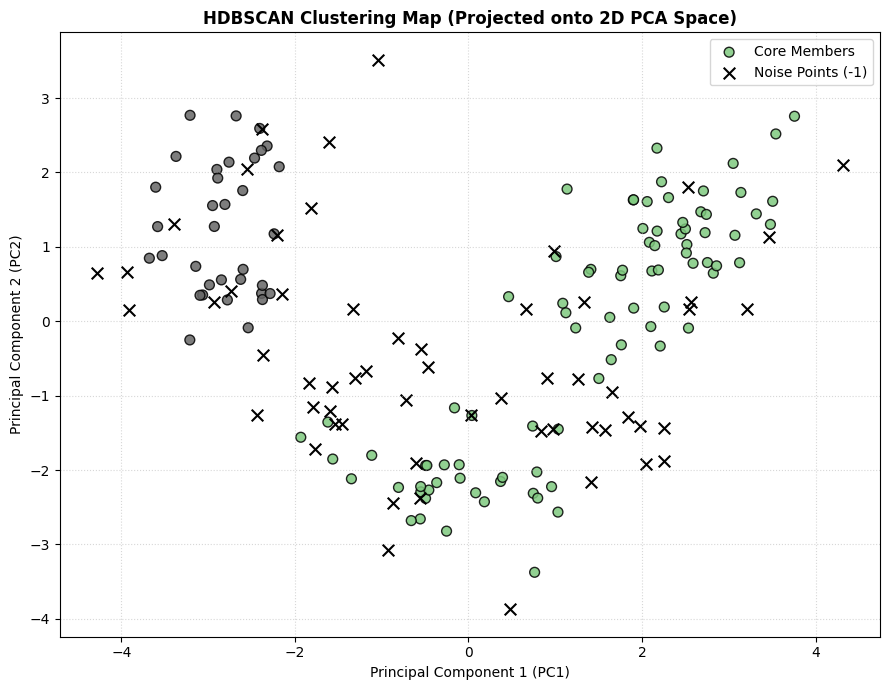

In [62]:
# Imports Scikit-Learn's HDBSCAN library
from sklearn.cluster import HDBSCAN

# Task 6: HDBSCAN Clustering and Evaluation
print("--- Task 6: HDBSCAN Clustering and Evaluation ---")

# Fits the HDBSCAN model using hyperparameter limits
hdbscan = HDBSCAN(min_cluster_size=5, min_samples=5)
hdbscan_labels = hdbscan.fit_predict(X_scaled)

# Extracts and analyzes clusters vs noise points
unique_labels_hd = set(hdbscan_labels)
num_clust_hd = len(unique_labels_hd) - (1 if -1 in unique_labels_hd else 0)
num_noise_hd = list(hdbscan_labels).count(-1)

print("--- HDBSCAN Execution Metrics ---")
print(f"Number of Clusters Discovered: {num_clust_hd}")
print(f"Number of Noise Points (-1): {num_noise_hd}")
print("---------------------------------\n")

# Styling for the plot
plt.figure(figsize=(9, 7))

# Filters noise and plot the core feats
filtered_noise_hd = hdbscan_labels != -1
scatter_hd = plt.scatter(
    X_pca[filtered_noise_hd, 0],
    X_pca[filtered_noise_hd, 1],
    c=hdbscan_labels[filtered_noise_hd],
    cmap='Accent',
    s=50,
    edgecolor='k',
    alpha=0.85,
    label='Core Members'
)

# Filters core feats and plots noise
filtered_core_hd = hdbscan_labels == -1
plt.scatter(
    X_pca[filtered_core_hd, 0],
    X_pca[filtered_core_hd, 1],
    color='black',
    marker='x',
    s=70,
    linewidth=1.5,
    label='Noise Points (-1)'
)

plt.title("HDBSCAN Clustering Map (Projected onto 2D PCA Space)", fontsize=12, fontweight='bold')
plt.xlabel("Principal Component 1 (PC1)", fontsize=10)
plt.ylabel("Principal Component 2 (PC2)", fontsize=10)
plt.legend(loc="upper right")
plt.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()


# Task 7: Hierarchical Clustering Dendrogram

The following code cell computes a single-linkage hierarchical clustering matrix using the 13D standardized dataset (X_scaled) and plots the resulting dendrogram.

- Computes a single-linkage hierarchical clustering matrix on the scaled Wine features.
- Plots a hierarchical clustering dendrogram to visualize how individual chemical profiles merge across distance thresholds, connecting the visual structure to HDBSCAN's stability extraction mechanics.

--- Task 7: Hierarchical Clustering Dendrogram ---


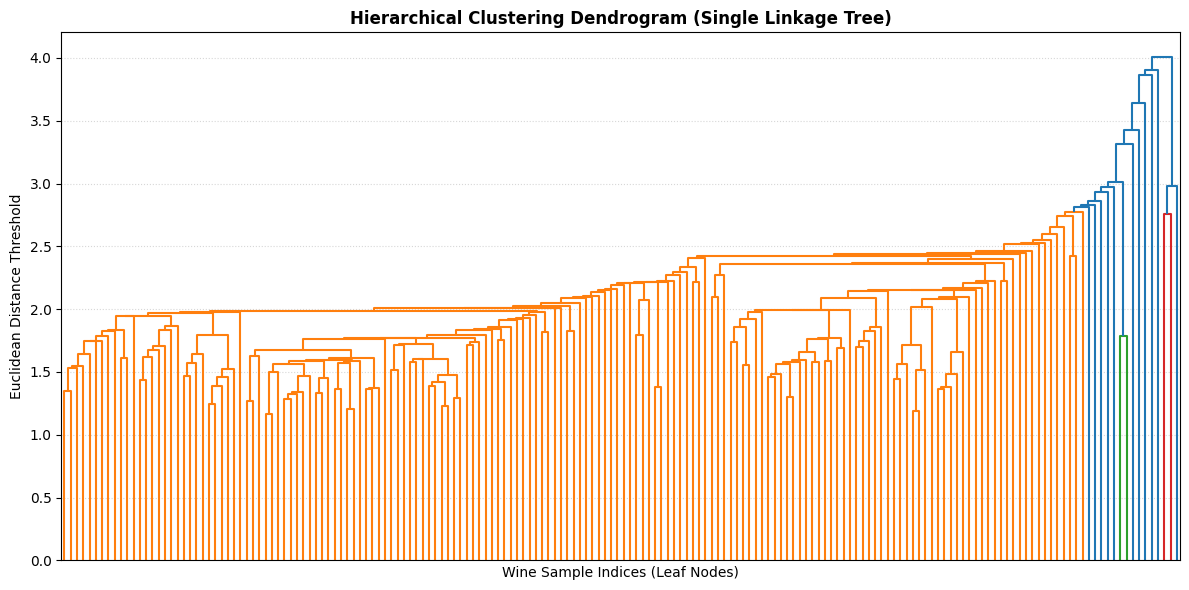

In [63]:
# Import needed functionalities from Scikit-Learn
from scipy.cluster.hierarchy import linkage, dendrogram

# Task 7: Hierarchical Clustering Dendrogram
print("--- Task 7: Hierarchical Clustering Dendrogram ---")

# Comput the hierarchical clustering matrix using single-linkage and for euclidean distance
linked = linkage(X_scaled, method='single', metric='euclidean')

# Styling for the plot
plt.figure(figsize=(12, 6))

# Generate the dendrogram and sets color_threshold=None For hierarchy coloring
dendrogram(
    linked,
    orientation='top',
    distance_sort='descending',
    leaf_rotation=90,
    leaf_font_size=8,
    no_labels=True,
    color_threshold=None # For hierarchy coloring
)

plt.title("Hierarchical Clustering Dendrogram (Single Linkage Tree)", fontsize=12, fontweight='bold')
plt.xlabel("Wine Sample Indices (Leaf Nodes)", fontsize=10)
plt.ylabel("Euclidean Distance Threshold", fontsize=10)
plt.grid(True, axis='y', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()


# Task 8: Supervised Classification and Algorithm Comparison

The following code cell combines the assignments from K-Means, DBSCAN, and HDBSCAN to train a supervised classifier (I chose Random Forest instead of Logistic Regression) to predict the ground-truth wine cultivars. The code will then perform an 80/20 train-test split for each set of labels, calculate the test accuracies, collect the original Silhouette Scores, and plot everything in a side-by-side comparison plot.

- Combines the cluster assignments generated by K-Means (k=3), DBSCAN, and HDBSCAN as pseudo-labels.
- Performs a stratified train/test split (80/20) on the Wine dataset and trains a supervised classifier (Random Forest) using these cluster labels to predict the actual ground-truth wine cultivars (Class 0, 1, 2).
- Plots the classification accuracy and Silhouette Scores for all three algorithms.

--- Task 8: Supervised Classification and Algorithm Comparison ---
--------------------------- Train/Test Start ---------------------------
K-Means (k=3) Labels - Classification Accuracy: 0.9722
DBSCAN Labels - Classification Accuracy: 0.7778
HDBSCAN Labels - Classification Accuracy: 0.6944
---------------------------- Train/Test End ----------------------------



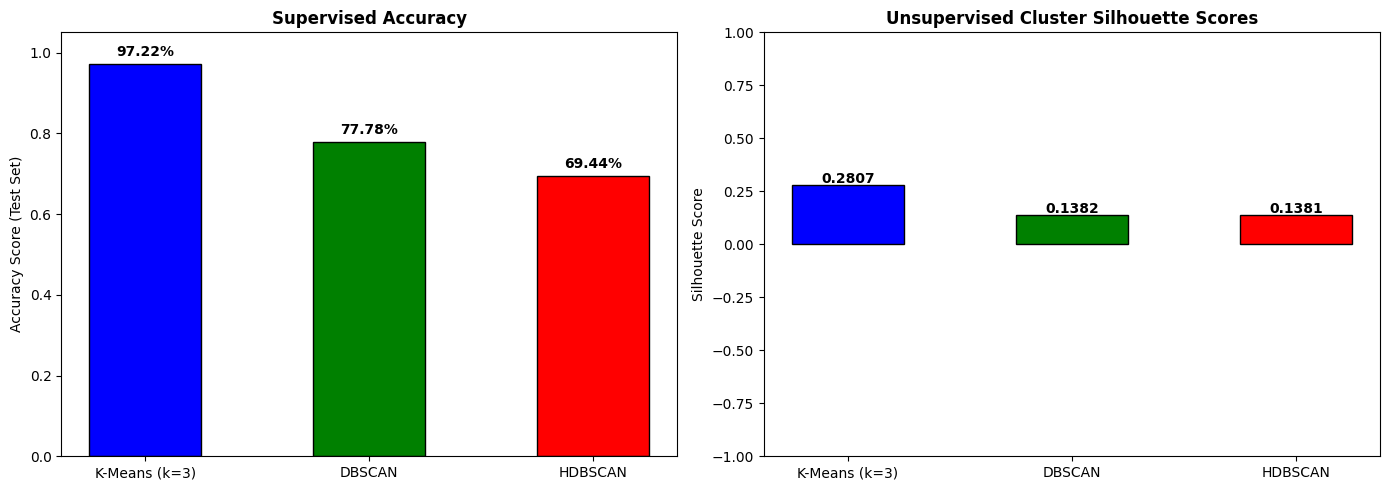

In [64]:
# Import needed functionalities from Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Task 8: Supervised Classification and Algorithm Comparison
print("--- Task 8: Supervised Classification and Algorithm Comparison ---")

# Create a dictionary for the 3 labels
labels_dict = {
    "K-Means (k=3)": kmeans_13f.labels_,
    "DBSCAN": dbscan_labels,
    "HDBSCAN": hdbscan_labels
}

# Create a dictionary for the silhouette scores
sil_dict = {
    "K-Means (k=3)": silhouette_score(X_scaled, kmeans_13f.labels_),
    "DBSCAN": silhouette_score(X_scaled, dbscan_labels),
    "HDBSCAN": silhouette_score(X_scaled, hdbscan_labels)
}

accuracy = {}

print("--------------------------- Train/Test Start ---------------------------")
# Iterate through each algo's pseudo-labels
for name, pseudo_labels in labels_dict.items():
    # I want to reshape pseudo-labels to simulate a 2D feat-matrix for the classifier
    X_pseudo = pseudo_labels.reshape(-1, 1)

    # Splits the data using an 80/20 split (20% for test) and I will also set the random seed as the same from before.
    # I set stratify along the target to keep balance identical in both of my sets.
    test_ratio = 0.2
    X_train, X_test, y_train, y_test = train_test_split(
        X_pseudo, y, test_size=test_ratio, random_state=seed, stratify=y
    )

    # Trains an RF Classifier on the cluster pseudo-labels
    rf_class = RandomForestClassifier(random_state=seed, n_estimators=100)
    rf_class.fit(X_train, y_train)

    # Evaluates accuracy on the test set
    predictions = rf_class.predict(X_test)
    acc = accuracy_score(y_test, predictions)
    accuracy[name] = acc

    print(f"{name} Labels - Classification Accuracy: {acc:.4f}")

print("---------------------------- Train/Test End ----------------------------\n")

# Styling for the plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
algorithms = list(labels_dict.keys())

# For ploy 1, this is for the supervised classification accuracy
axes[0].bar(algorithms, [accuracy[alg] for alg in algorithms], color=['blue', 'green', 'red'], edgecolor='k', width=0.5)
axes[0].set_title("Supervised Accuracy", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Accuracy Score (Test Set)", fontsize=10)
axes[0].set_ylim(0, 1.05)
for i, v in enumerate(algorithms):
    axes[0].text(i, accuracy[v] + 0.02, f"{accuracy[v]:.2%}", ha='center', fontweight='bold')

# For plot 2, this is for the unsupervised silhouette scores
axes[1].bar(algorithms, [sil_dict[alg] for alg in algorithms], color=['blue', 'green', 'red'], edgecolor='k', width=0.5)
axes[1].set_title("Unsupervised Cluster Silhouette Scores", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Silhouette Score", fontsize=10)
axes[1].set_ylim(-1, 1)

# Adds text labels on top of the bars
# IMPORTANT: I had to Google this since I had trouble with placing the labels on top!
for i, v in enumerate(algorithms):
    axes[1].text(i, sil_dict[v] + 0.01, f"{sil_dict[v]:.4f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()
